# Sampler features

This notebook uses the sinusoid model from the
[quickstart](sinusoid_quickstart.ipynb) to show the `PTSampler` options
you're most likely to reach for:

1. **Tempering** on a posterior with two modes, and the temperature ladder.
2. **Periodic parameters** that wrap around instead of hitting a wall.
3. **Starting covariance and parameter groups** for the adaptive proposals.
4. **A custom proposal** that jumps between modes on its own.
5. **Checkpoint and resume**, with frozen adaptation (`num_adapt`).

The data here are longer than in the quickstart (2,000 samples over 100 s),
so the frequency peaks are much narrower. Besides `impulse-mcmc`, this
notebook uses `matplotlib`.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np

from impulse import CheckpointMismatchError, PTSampler

LOW = np.array([0.0, 0.05, 0.0])  # amplitude, frequency (Hz), phase (rad)
HIGH = np.array([5.0, 5.0, 2 * np.pi])
SIGMA = 1.0
t = np.linspace(0.0, 100.0, 2000, endpoint=False)
noise = SIGMA * np.random.default_rng(23).standard_normal(t.size)


def sinusoid(a, f, phi):
    return a * np.sin(2 * np.pi * f * t + phi)


def make_log_likelihood(data):
    def log_likelihood(x):
        residual = data - sinusoid(*x)
        return -0.5 * np.dot(residual, residual) / SIGMA**2

    return log_likelihood


def log_prior(x):
    return 0.0 if np.all((x >= LOW) & (x <= HIGH)) else -np.inf

## 1. Tempering on a two-mode posterior

The data contain **two** sinusoids of nearly equal strength, at 1.3 Hz and
2.9 Hz, but we fit a model with **one**. The posterior then has two modes,
one per signal, with almost equal weight.

To see them, fix the frequency and solve for the best amplitude and phase,
which is a linear least-squares problem: $A\sin(2\pi f t + \phi) = a_s
\sin(2\pi f t) + a_c \cos(2\pi f t)$ with $a_s = A\cos\phi$ and
$a_c = A\sin\phi$. The resulting best log-likelihood at each frequency is
a periodogram. We reuse `linear_fit` for a custom proposal in section 4.

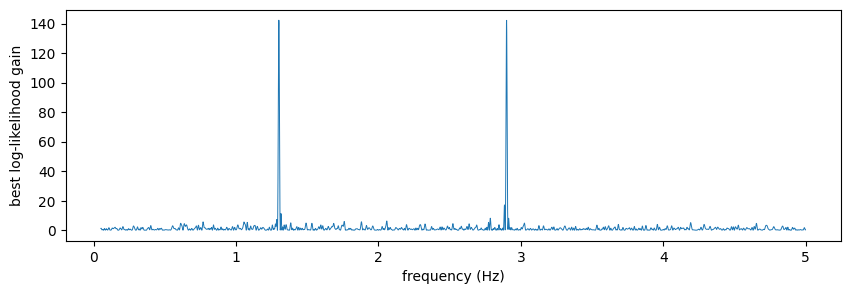

In [2]:
two_signal_data = sinusoid(0.5, 1.3, 0.05) + sinusoid(0.566, 2.9, 1.0) + noise
log_likelihood_2 = make_log_likelihood(two_signal_data)


def linear_fit(f, data):
    """Best (a_s, a_c) at frequency f, their covariance, and the log-likelihood gain."""
    design = np.stack([np.sin(2 * np.pi * f * t), np.cos(2 * np.pi * f * t)], axis=1)
    normal = design.T @ design
    projection = design.T @ data
    mean = np.linalg.solve(normal, projection)
    return mean, SIGMA**2 * np.linalg.inv(normal), 0.5 * projection @ mean / SIGMA**2


freqs = np.arange(0.05, 5.0, 0.001)
gain = np.array([linear_fit(f, two_signal_data)[2] for f in freqs])

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(freqs, gain, lw=0.7)
ax.set(xlabel="frequency (Hz)", ylabel="best log-likelihood gain");

Each peak is about 0.01 Hz wide, out of a 5 Hz prior range. We run two
single-temperature samplers and two with 8 temperatures, each from a
different random start, and record the fraction of time each spends in
either mode.

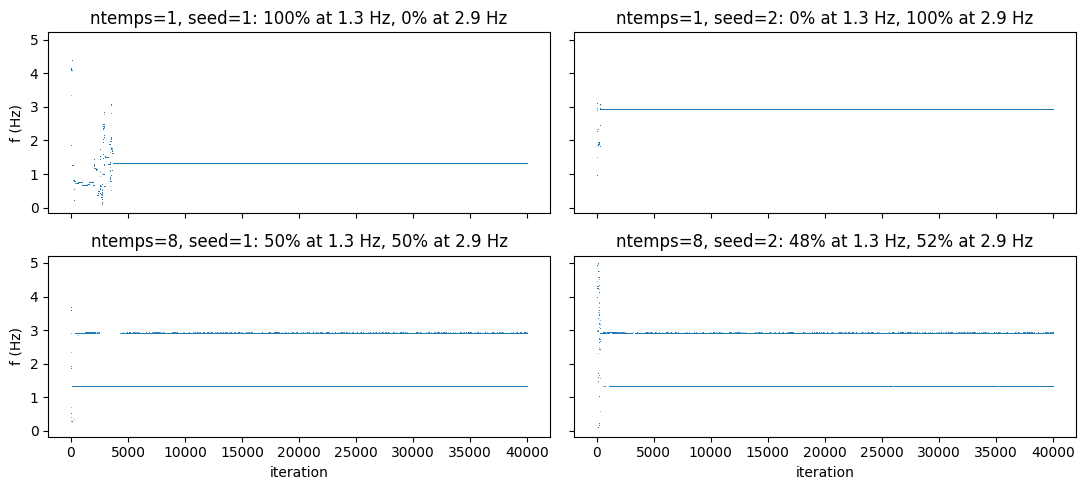

In [3]:
def mode_fractions(frequencies):
    return [np.mean(np.abs(frequencies - f0) < 0.02) for f0 in (1.3, 2.9)]


fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharex=True, sharey=True)
tempered = {}
for row, ntemps in enumerate((1, 8)):
    for col, seed in enumerate((1, 2)):
        sampler = PTSampler(
            ndim=3,
            lnlike=log_likelihood_2,
            lnprior=log_prior,
            ntemps=ntemps,
            seed=seed,
            periodic={2: 2 * np.pi},  # see section 2
            outdir=f"chains_modes_{ntemps}_{seed}",
            verbose=False,
        )
        start = np.random.default_rng(100 + seed).uniform(LOW, HIGH)
        sampler.sample(start, num_iterations=40_000)
        f_chain = sampler.load_chain()["samples"][0][:, 1]
        tempered[ntemps, seed] = sampler
        low, high = mode_fractions(f_chain[10_000:])
        ax = axes[row, col]
        ax.plot(f_chain, ",", alpha=0.5)
        ax.set_title(f"ntemps={ntemps}, seed={seed}: {low:.0%} at 1.3 Hz, {high:.0%} at 2.9 Hz")
for ax in axes[:, 0]:
    ax.set_ylabel("f (Hz)")
for ax in axes[1]:
    ax.set_xlabel("iteration")
fig.tight_layout()

Each single-temperature chain settles into whichever mode it finds first
and never leaves, so the two runs give completely different answers. With
8 temperatures, the hot chains move between the modes and swaps carry
those moves down to the cold chain: both runs spend about half their time
in each mode, and agree.

### The ladder

The ladder starts out geometric and adapts during the run so that
neighbouring temperatures swap at similar rates. `max_temp` sets the top
of the starting ladder, `ladder=` fixes it completely, and
`inf_temp=True` makes the hottest chain sample the prior, which keeps
feeding well-spread states down the ladder.

In [4]:
rates = tempered[8, 1].chain_acceptance_rates()
print("adapted ladder:", np.round(rates["temperatures"], 1))
print("swap rates:    ", np.round(rates["pt_swap"], 2))

for options in ({}, {"max_temp": 1000.0}, {"inf_temp": True}):
    sampler = PTSampler(
        ndim=3,
        lnlike=log_likelihood_2,
        lnprior=log_prior,
        ntemps=8,
        outdir="chains_ladder",
        verbose=False,
        **options,
    )
    print(f"starting ladder {str(options):<22}", np.round(sampler.ptstate.ladder, 1))

adapted ladder: [ 1.   1.7  2.8  3.7  7.  22.9 29.7 65.3]
swap rates:     [0.83 0.66 0.72 0.75 0.34 0.53 0.59]
starting ladder {}                     [ 1.   1.8  3.3  6.  10.9 19.8 35.9 65.3]
starting ladder {'max_temp': 1000.0}   [   1.     2.7    7.2   19.3   51.8  138.9  372.8 1000. ]
starting ladder {'inf_temp': True}     [ 1.   1.8  3.3  6.  10.9 19.8 35.9  inf]


## 2. Periodic parameters

The phase is an angle: 0 and $2\pi$ are the same point. Here the true
phase is 0.05 rad, so the posterior straddles the boundary, with part of
its mass just above 0 and the rest just below $2\pi$.

Without `periodic`, the sampler treats both ends of the prior as walls, so
a single chain stays on the side it started on. With
`periodic={2: 2 * np.pi}` (parameter index: period), the phase wraps
around, and small steps cross the boundary freely.

no periodic: 0% of samples just below 2 pi


periodic={2: 2 * np.pi}: 78% of samples just below 2 pi


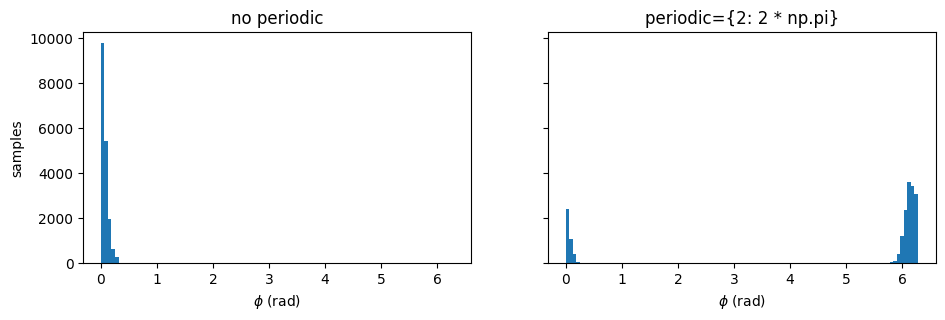

In [5]:
one_signal_data = sinusoid(0.5, 1.3, 0.05) + noise
log_likelihood_1 = make_log_likelihood(one_signal_data)
truth_1 = np.array([0.5, 1.3, 0.05])

fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
cases = (("no periodic", None), ("periodic={2: 2 * np.pi}", {2: 2 * np.pi}))
for ax, (label, periodic) in zip(axes, cases):
    sampler = PTSampler(
        ndim=3,
        lnlike=log_likelihood_1,
        lnprior=log_prior,
        ntemps=1,
        seed=1,
        periodic=periodic,
        outdir="chains_periodic",
        verbose=False,
    )
    sampler.sample(truth_1, num_iterations=20_000)
    phase = sampler.load_chain()["samples"][0][2_000:, 2]
    ax.hist(phase, bins=np.linspace(0, 2 * np.pi, 100))
    ax.set(xlabel=r"$\phi$ (rad)", title=label)
    print(f"{label}: {np.mean(phase > np.pi):.0%} of samples just below 2 pi")
axes[0].set_ylabel("samples");

Without wrapping, the chain misses the part of the posterior just below
$2\pi$ entirely. Tempering would eventually carry the chain across, but
`periodic` gets it right directly. Use it for every angle-like parameter;
a scalar is the period starting at 0, and a `(low, high)` pair sets both
ends.

## 3. Starting covariance and parameter groups

AM and SCAM propose steps from a covariance learned from the chain
history. Before there is any history, they use `sample_cov`, which
defaults to the identity. Here the posterior widths are about 0.0003 Hz
in frequency and 0.03 in amplitude, so the first proposals are far too
large. If you can estimate the posterior covariance in advance, for
example from the Fisher matrix, pass it in.

Fisher-matrix standard deviations: [0.03162284 0.00034869 0.12640727]


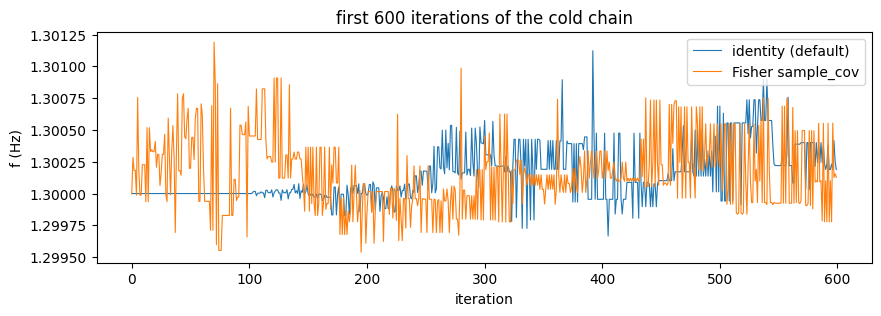

In [6]:
a, f, phi = truth_1
argument = 2 * np.pi * f * t + phi
derivatives = np.stack(
    [np.sin(argument), a * 2 * np.pi * t * np.cos(argument), a * np.cos(argument)], axis=1
)
fisher_cov = np.linalg.inv(derivatives.T @ derivatives / SIGMA**2)
print("Fisher-matrix standard deviations:", np.sqrt(np.diag(fisher_cov)))

fig, ax = plt.subplots(figsize=(10, 3))
starts = (("identity (default)", {}), ("Fisher sample_cov", {"sample_cov": fisher_cov}))
for label, options in starts:
    sampler = PTSampler(
        ndim=3,
        lnlike=log_likelihood_1,
        lnprior=log_prior,
        ntemps=4,
        seed=1,
        periodic={2: 2 * np.pi},
        outdir="chains_cov",
        verbose=False,
        **options,
    )
    sampler.sample(truth_1, num_iterations=600)
    ax.plot(sampler.load_chain()["samples"][0][:, 1], lw=0.8, label=label)
ax.set(xlabel="iteration", ylabel="f (Hz)", title="first 600 iterations of the cold chain")
ax.legend();

With the identity, almost every early proposal is rejected and the chain
sits still until adaptation has collected enough history. With the Fisher
covariance it mixes from the first iteration. Here adaptation catches up
within a few hundred iterations, so this matters most when each
likelihood call is expensive.

**Groups.** By default every AM, SCAM and DE move updates all parameters
together. `groups` is a list of index lists; each move picks one group and
updates only those parameters, using that block of the covariance. That
helps when blocks of parameters are only weakly coupled, such as the noise
parameters of separate detectors. On this 3-parameter model the single
default group is the right choice; the syntax is:

In [7]:
grouped = PTSampler(
    ndim=3,
    lnlike=log_likelihood_1,
    lnprior=log_prior,
    ntemps=4,
    seed=1,
    periodic={2: 2 * np.pi},
    groups=[[0, 1, 2], [1, 2]],  # all parameters, or frequency and phase only
    outdir="chains_groups",
    verbose=False,
)
grouped.sample(truth_1, num_iterations=20_000)
for name, report in grouped.proposal_acceptance_rates().items():
    print(f"{name:>5}: {report['rate']:.2f}")

   am: 0.05
 scam: 0.31
   de: 0.46


## 4. A custom proposal that jumps between modes

Tempering isn't the only way between modes: a proposal that knows where
the modes are can jump there directly. This one is an *independence*
proposal built from the periodogram in section 1:

1. Draw a frequency bin with probability proportional to
   $e^{\text{gain}}$, mixed with 10% uniform so every frequency stays
   reachable, then a frequency uniformly within the bin.
2. Draw $(a_s, a_c)$ from the Gaussian that the linear fit gives at that
   frequency, and convert to amplitude and phase.

A proposal returns the new point and
$q_{xy} = \log q(x \mid y) - \log q(y \mid x)$. For an independence
proposal that is simply $\log q(x) - \log q(y)$. Going from $(a_s, a_c)$
to polar $(A, \phi)$ multiplies the density by the Jacobian $A$, so
$\log A$ appears in $\log q$.

This is the same idea as an F-statistic proposal for gravitational-wave
searches: maximize over the parameters that enter linearly, and draw the
rest from the resulting map.

one temperature + periodogram_jump: 47% at 1.3 Hz, 53% at 2.9 Hz
              am: 0.00 of 5703 calls
            scam: 0.03 of 11444 calls
              de: 0.30 of 19027 calls
periodogram_jump: 0.22 of 3826 calls


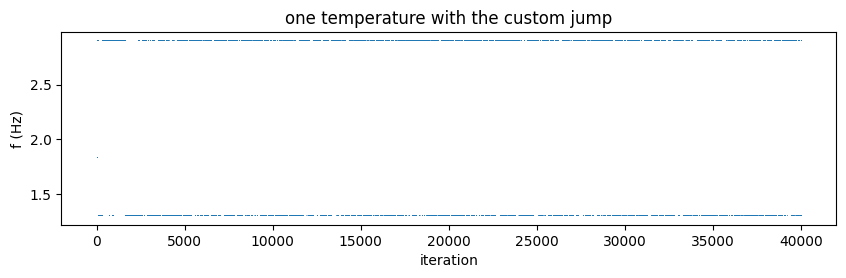

In [8]:
class PeriodogramJump:
    """Independence proposal: frequency from a periodogram map, (A, phi) from a linear fit."""

    __name__ = "periodogram_jump"  # labels acceptance reports and the resume check

    def __init__(self, data, f_low=0.05, f_high=5.0, n_bins=2000, uniform_fraction=0.1):
        self.data = data
        self.edges = np.linspace(f_low, f_high, n_bins + 1)
        self.width = self.edges[1] - self.edges[0]
        centres = 0.5 * (self.edges[1:] + self.edges[:-1])
        gain = np.array([linear_fit(f, data)[2] for f in centres])
        weights = np.exp(gain - gain.max())
        self.weights = (1 - uniform_fraction) * weights / weights.sum() + uniform_fraction / n_bins
        self.cumulative = np.cumsum(self.weights)

    def log_density(self, x):
        a, f, phi = x
        k = min(int((f - self.edges[0]) / self.width), len(self.weights) - 1)
        mean, cov, _ = linear_fit(f, self.data)
        z = np.array([a * np.cos(phi), a * np.sin(phi)]) - mean
        log_norm = -0.5 * np.log(np.linalg.det(2 * np.pi * cov))
        log_gauss = -0.5 * z @ np.linalg.solve(cov, z) + log_norm
        return np.log(self.weights[k] / self.width) + log_gauss + np.log(a)

    def __call__(self, chain_stats):
        rng = chain_stats.rng  # always use the chain's own generator
        k = min(np.searchsorted(self.cumulative, rng.random()), len(self.weights) - 1)
        f = self.edges[k] + self.width * rng.random()
        mean, cov, _ = linear_fit(f, self.data)
        a_s, a_c = rng.multivariate_normal(mean, cov)
        x = chain_stats.current_sample
        y = np.array([np.hypot(a_s, a_c), f, np.arctan2(a_c, a_s) % (2 * np.pi)])
        return y, self.log_density(x) - self.log_density(y)


jump = PeriodogramJump(two_signal_data)
single = PTSampler(
    ndim=3,
    lnlike=log_likelihood_2,
    lnprior=log_prior,
    ntemps=1,
    seed=1,
    periodic={2: 2 * np.pi},
    outdir="chains_jump",
    verbose=False,
)
single.add_custom_jump(jump, weight=10)
single.sample(np.random.default_rng(101).uniform(LOW, HIGH), num_iterations=40_000)

f_chain = single.load_chain()["samples"][0][:, 1]
low, high = mode_fractions(f_chain[10_000:])
print(f"one temperature + periodogram_jump: {low:.0%} at 1.3 Hz, {high:.0%} at 2.9 Hz")
for name, report in single.proposal_acceptance_rates().items():
    print(f"{name:>16}: {report['rate']:.2f} of {report['calls']} calls")

fig, ax = plt.subplots(figsize=(10, 2.5))
ax.plot(f_chain, ",", alpha=0.5)
ax.set(xlabel="iteration", ylabel="f (Hz)", title="one temperature with the custom jump");

A single chain now visits both modes in the same proportions as the
tempered runs in section 1.

AM and SCAM almost never succeed here. Their covariance is learned from a
history that spans both modes, so their steps are as wide as the gap
between the modes and land in neither. DE, which reuses differences
between past samples, still makes local moves and jumps between the modes.
The two approaches combine well: an informed proposal for the moves you can
design, tempering for the ones you can't.

## 5. Checkpoint and resume

Every `save_freq` iterations the sampler writes a checkpoint
(`sampler_checkpoint.npz` and `.json`). Loading it runs no code. To
resume, build the sampler again exactly as before, including any custom
proposals registered with the same weights, and pass `resume=True`. A
resumed run is bit-for-bit identical to one that was never interrupted.

This example also freezes adaptation after 5,000 iterations with
`num_adapt`. From then on the covariance, the DE history and the ladder
stop changing, so the chain is exactly Markovian; treat the first
`num_adapt` iterations as warm-up and discard them.

In [9]:
def make_sampler(outdir, resume=False, with_jump=True):
    sampler = PTSampler(
        ndim=3,
        lnlike=log_likelihood_2,
        lnprior=log_prior,
        ntemps=4,
        seed=7,
        periodic={2: 2 * np.pi},
        num_adapt=5_000,
        save_freq=1_000,
        outdir=outdir,
        resume=resume,
        verbose=False,
    )
    if with_jump:
        sampler.add_custom_jump(jump, weight=10)
    return sampler


start = np.array([0.5, 1.3, 0.1])
make_sampler("chains_uninterrupted").sample(start, num_iterations=20_000)

make_sampler("chains_resumed").sample(start, num_iterations=10_000)  # stops halfway
make_sampler("chains_resumed", resume=True).sample(start, num_iterations=20_000)

full = make_sampler("chains_uninterrupted").load_chain()
resumed = make_sampler("chains_resumed").load_chain()
print("identical:", all(np.array_equal(full[key], resumed[key]) for key in full))
print("files:", sorted(os.listdir("chains_resumed")))

identical: True
files: ['chain_0.bin', 'chain_1.bin', 'chain_2.bin', 'chain_3.bin', 'chain_acceptance.json', 'sampler_checkpoint.json', 'sampler_checkpoint.npz']


If the rebuilt sampler doesn't match the checkpoint, here because the
custom proposal wasn't registered again, resuming raises an error instead
of silently continuing with a different sampler:

In [10]:
try:
    unregistered = make_sampler("chains_resumed", resume=True, with_jump=False)
    unregistered.sample(start, num_iterations=30_000)
except CheckpointMismatchError as error:
    print("CheckpointMismatchError:", error)

CheckpointMismatchError: proposal mismatch on chain 0: checkpoint registered ['am', 'scam', 'de', 'periodogram_jump'] but the reconstructed sampler has ['am', 'scam', 'de']. missing proposal(s) ['periodogram_jump']; register the same proposals in the same order before resuming.


Chains are stored in a binary format by default. Pass
`chain_format="text"` for plain-text chain files instead; `load_chain`
reads either.

## Summary

| Option | What it does |
|---|---|
| `ntemps`, `max_temp`, `ladder`, `inf_temp` | Tempering: hot chains cross between modes and swaps bring the results down |
| `periodic={index: period}` | Wraps angle-like parameters |
| `sample_cov` | Starting covariance for AM and SCAM, e.g. from a Fisher matrix |
| `groups` | Blocks of parameters that the adaptive moves update separately |
| `add_custom_jump(proposal, weight)` | Your own proposal, returning `(new_point, qxy)` |
| `num_adapt` | Stops all adaptation after that many iterations |
| `save_freq`, `resume=True` | Checkpoint interval, and bit-exact resume |
| `chain_format` | `"binary"` (default) or `"text"` chain files |

See the user guide pages on parallel tempering, custom proposals and
checkpointing for the details of each.